# Portfolio 3: Advanced ML and Deep Learning
**Pham Quang Minh | Student ID: 104999568**

COS40007 Artificial Intelligence Engineering

GitHub: https://github.com/theh9j/COS40007

Started: 1 November 2026

**Checkpoint 5: both traditional baselines and both ANN runs are complete.**
The final report and reflection are still pending.

## Problem and data
Continue the Concrete Compressive Strength project using **option 3d: a tabular ANN**.
The working target is the four strength groups from Portfolio 2.

The checked data has 1,005 records and eight original inputs. The existing recipe
split has 676 training records and 329 test records. Each training class has 169
records. No missing values or shared train/test recipes were found.

The data is in `data/concrete_partitioned.csv`. The verification record is in
`checks/iteration-01-data-audit.json`. Keep target strength, class labels and ID
columns out of the model inputs.

## Part A.1 - Prepare the inputs
Keep the eight original ingredient/age measurements and the four existing strength
classes. Use the saved recipe split from Portfolio 2: 676 training rows and 329 test
rows. No target, ID or partition columns are used as inputs.

Class boundaries are kept as the fixed task definition from Portfolio 2; they are
not recalculated on test data. Earlier portfolios inspected this dataset, so these
results still need external validation.

In [1]:
from pathlib import Path
import json
import hashlib
import pickle
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
FEATURES = ['cement', 'slag', 'fly_ash', 'water', 'superplasticizer',
            'coarse_aggregate', 'fine_aggregate', 'age']
CLASS_NAMES = ['Lower', 'Lower-middle', 'Upper-middle', 'Higher']
DATA_PATH = Path('data/concrete_partitioned.csv')
audit_01 = json.loads(Path('checks/iteration-01-data-audit.json').read_text())
source_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert source_hash == audit_01['copied_sha256'], 'The checked dataset has changed.'
data = pd.read_csv(DATA_PATH)
assert data.source_row.is_unique and data.notna().all().all()
train = data.loc[data.partition.eq('train')].copy()
test = data.loc[data.partition.eq('test')].copy()
X_train, X_test = train[FEATURES], test[FEATURES]
y_train = train.strength_class_code.astype(int)
y_test = test.strength_class_code.astype(int)
groups = train.recipe_group.to_numpy()
assert X_train.shape == (676, 8) and X_test.shape == (329, 8)
assert set(groups).isdisjoint(test.recipe_group)
assert np.isfinite(data[FEATURES].to_numpy()).all()
for folder in ['results', 'figures', 'models', 'checks']:
    Path(folder).mkdir(exist_ok=True)
print('Training shape:', X_train.shape, '| Target shape:', y_train.shape)
print('Test shape:', X_test.shape, '| Target shape:', y_test.shape)
print('Inputs:', ', '.join(FEATURES))
print('Shared training/test recipes: 0')

Training shape: (676, 8) | Target shape: (676,)
Test shape: (329, 8) | Target shape: (329,)
Inputs: cement, slag, fly_ash, water, superplasticizer, coarse_aggregate, fine_aggregate, age
Shared training/test recipes: 0


## Part A.2 - Random Forest and five-fold checks
A Random Forest combines predictions from many decision trees. Start with 200
trees and at least two training records per leaf. These settings are fixed for
this baseline; no search uses the test results.

StandardScaler is inside the pipeline, so it learns from training rows only.
Trees usually do not need scaling, but this sets up a consistent workflow for the
MLP next. Each CV fold also learns its own scaler.

Five-fold CV checks different groups of training recipes. Accuracy is the fraction
predicted correctly. Weighted F1 combines precision and recall, weighting classes
by their number of records. Higher scores are better.

In [2]:
baseline = Pipeline([
    ('scale', StandardScaler()),
    ('model', RandomForestClassifier(n_estimators=200, min_samples_leaf=2,
                                      random_state=SEED, n_jobs=1))
])
cv = GroupKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(cv.split(X_train, y_train, groups))
for fit_idx, valid_idx in folds:
    assert set(groups[fit_idx]).isdisjoint(groups[valid_idx])

cv_scores = cross_validate(baseline, X_train, y_train, cv=folds,
    scoring={'accuracy': 'accuracy', 'f1_weighted': 'f1_weighted'},
    return_estimator=True, n_jobs=1, error_score='raise')

# Verify every scaler used only its fold's fitting rows.
fold_rows, assignment_rows = [], []
for fold, ((fit_idx, valid_idx), fitted) in enumerate(
        zip(folds, cv_scores['estimator']), start=1):
    np.testing.assert_allclose(fitted.named_steps['scale'].mean_,
                               X_train.iloc[fit_idx].mean().to_numpy())
    fold_rows.append({'fold': fold,
        'accuracy': float(cv_scores['test_accuracy'][fold - 1]),
        'f1_weighted': float(cv_scores['test_f1_weighted'][fold - 1]),
        'fit_rows': len(fit_idx), 'validation_rows': len(valid_idx),
        'shared_recipes': 0})
    for source_id in train.iloc[valid_idx].source_row:
        assignment_rows.append({'source_row': int(source_id), 'validation_fold': fold})
fold_results = pd.DataFrame(fold_rows)
fold_results.to_csv('results/random_forest_cv.csv', index=False)
pd.DataFrame(assignment_rows).sort_values('source_row').to_csv(
    'checks/cv_recipe_folds.csv', index=False)
print(fold_results[['fold', 'accuracy', 'f1_weighted']].round(4).to_string(index=False))
print(f'Mean CV accuracy: {fold_results.accuracy.mean():.2%}')
print(f'Mean CV weighted F1: {fold_results.f1_weighted.mean():.4f}')

 fold  accuracy  f1_weighted
    1    0.6328       0.6389
    2    0.7200       0.7208
    3    0.7462       0.7454
    4    0.6471       0.6446
    5    0.7121       0.7128
Mean CV accuracy: 69.16%
Mean CV weighted F1: 0.6925


## Part A.3 - Check the separate test set
Fit the fixed baseline on all training recipes, then evaluate it on the saved test
recipes. Keep these results as the reference for the MLP. Do not change settings
just to improve this test score.

In [3]:
baseline.fit(X_train, y_train)
np.testing.assert_allclose(baseline.named_steps['scale'].mean_,
                           X_train.mean().to_numpy())
train_prediction = baseline.predict(X_train)
test_prediction = baseline.predict(X_test)
assert set(test_prediction).issubset(range(4))
metrics = {
    'model': 'Random Forest',
    'train_accuracy': float(accuracy_score(y_train, train_prediction)),
    'cv_accuracy_mean': float(fold_results.accuracy.mean()),
    'cv_accuracy_sd': float(fold_results.accuracy.std(ddof=1)),
    'cv_f1_weighted_mean': float(fold_results.f1_weighted.mean()),
    'cv_f1_weighted_sd': float(fold_results.f1_weighted.std(ddof=1)),
    'test_accuracy': float(accuracy_score(y_test, test_prediction)),
    'test_f1_weighted': float(f1_score(y_test, test_prediction,
                                      average='weighted', zero_division=0))
}
print(f'Test accuracy: {metrics["test_accuracy"]:.2%}')
print(f'Test weighted F1: {metrics["test_f1_weighted"]:.4f}')
print(f'Training accuracy: {metrics["train_accuracy"]:.2%}')
print(classification_report(y_test, test_prediction, labels=range(4),
    target_names=CLASS_NAMES, digits=3, zero_division=0))
pd.DataFrame([metrics]).to_csv('results/model_comparison.csv', index=False)
pd.DataFrame({'source_row': test.source_row.to_numpy(),
              'actual_class': y_test.to_numpy(),
              'predicted_class': test_prediction}).to_csv(
    'results/random_forest_test_predictions.csv', index=False)

Test accuracy: 78.12%
Test weighted F1: 0.7805
Training accuracy: 97.19%
              precision    recall  f1-score   support

       Lower      0.895     0.883     0.889        77
Lower-middle      0.649     0.667     0.658        72
Upper-middle      0.716     0.674     0.695        86
      Higher      0.847     0.883     0.865        94

    accuracy                          0.781       329
   macro avg      0.777     0.777     0.776       329
weighted avg      0.781     0.781     0.781       329



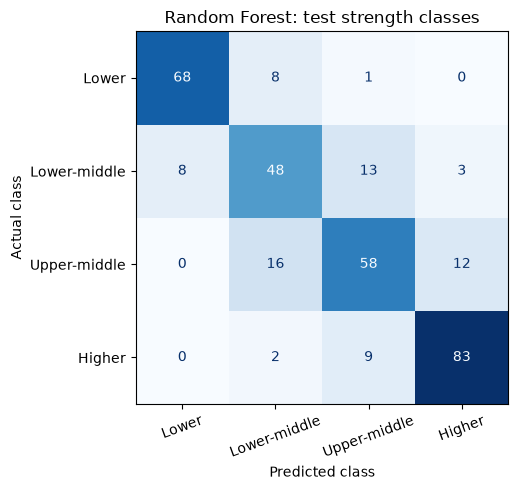

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 5))
ConfusionMatrixDisplay.from_predictions(y_test, test_prediction,
    labels=range(4), display_labels=CLASS_NAMES, cmap='Blues',
    values_format='d', colorbar=False, ax=ax, xticks_rotation=20)
ax.set_title('Random Forest: test strength classes')
ax.set_xlabel('Predicted class')
ax.set_ylabel('Actual class')
fig.tight_layout()
fig.savefig('figures/random_forest_confusion_matrix.png', dpi=180)
plt.show()
plt.close(fig)

## Part A.4 - Save and verify the baseline
Save the whole pipeline, including its fitted scaler. Check that loading our own
saved file produces exactly the same predictions. The fold assignments are also
saved so the next model can use the same five-fold comparison.

In [5]:
model_path = Path('models/random_forest_baseline.pkl')
with model_path.open('wb') as stream:
    pickle.dump(baseline, stream, protocol=pickle.HIGHEST_PROTOCOL)
# Load only the model file created by this notebook.
with model_path.open('rb') as stream:
    restored = pickle.load(stream)
np.testing.assert_array_equal(restored.predict(X_test), test_prediction)
assignment = pd.read_csv('checks/cv_recipe_folds.csv')
assert assignment.source_row.is_unique and len(assignment) == len(train)
metadata = {
    'student_id': '104999568', 'name': 'Pham Quang Minh',
    'github': 'https://github.com/theh9j/COS40007',
    'iteration': 2, 'date': '2026-11-01', 'seed': SEED,
    'features': FEATURES, 'class_names': CLASS_NAMES,
    'class_cutoffs_MPa': audit_01['class_cutoffs_MPa'],
    'label_policy': 'Fixed class definition inherited from Portfolio 2',
    'source_sha256': source_hash,
    'train_shape': list(X_train.shape), 'test_shape': list(X_test.shape),
    'cv': '5-fold GroupKFold by recipe; seed 42; training partition only',
    'cv_scalers_fit_on_fold_training_only': True,
    'final_scaler_fit_on_training_only': True,
    'shared_train_test_recipes': 0, 'shared_cv_recipes': 0,
    'saved_model_predictions_match': True,
    'model_parameters': baseline.named_steps['model'].get_params(),
    'metrics': metrics,
    'versions': {'python': platform.python_version(), 'sklearn': sklearn.__version__,
                 'numpy': np.__version__, 'pandas': pd.__version__},
    'ai_assistance': 'Baseline code drafting, explanations and verification'
}
Path('checks/iteration-02-checks.json').write_text(json.dumps(metadata, indent=2))
print('Saved model, CV scores, fold assignments, test predictions and checks.')
print('Training-only scaling and saved-model checks passed.')

Saved model, CV scores, fold assignments, test predictions and checks.
Training-only scaling and saved-model checks passed.


## Random Forest baseline results
The Random Forest correctly classified **78.1%** of test records, with weighted F1 **0.781**. Across five recipe-group folds, mean accuracy was **69.2%** and mean weighted F1 was **0.693**. Training accuracy was **97.2%**; the difference from CV performance suggests that training results are optimistic.

These results provide the reference for the MLP comparison below.

## Part A.5 - Add an MLP classifier
An MLP is a neural network for tabular data. Start with the supplied teaching
example's two hidden layers (100 and 50 units), ReLU, Adam and up to 500 iterations.
The settings are fixed before checking test performance.

Use the same eight inputs, labels, recipe split and five saved CV folds as the
Random Forest. StandardScaler stays inside the pipeline. Internal random validation
is disabled so it cannot split related recipes. Any convergence warnings are
recorded rather than hidden.

Reference: the supplied `MLP_Classifcation.ipynb`, adapted from Iris to concrete data.

In [6]:
import warnings
from sklearn.neural_network import MLPClassifier
from sklearn.exceptions import ConvergenceWarning

# Reconstruct the exact saved folds instead of drawing another random split.
saved_folds = pd.read_csv('checks/cv_recipe_folds.csv')
assert saved_folds.source_row.is_unique
fold_id = train.source_row.map(
    saved_folds.set_index('source_row').validation_fold).to_numpy()
assert not pd.isna(fold_id).any()
mlp_folds = [(np.flatnonzero(fold_id != k), np.flatnonzero(fold_id == k))
             for k in range(1, 6)]
for (a, b), (old_a, old_b) in zip(mlp_folds, folds):
    np.testing.assert_array_equal(a, old_a)
    np.testing.assert_array_equal(b, old_b)
    assert set(groups[a]).isdisjoint(groups[b])

mlp = Pipeline([
    ('scale', StandardScaler()),
    ('model', MLPClassifier(hidden_layer_sizes=(100, 50), activation='relu',
        solver='adam', max_iter=500, early_stopping=False, random_state=SEED))
])
with warnings.catch_warnings(record=True) as cv_warnings:
    warnings.simplefilter('always', ConvergenceWarning)
    mlp_cv = cross_validate(mlp, X_train, y_train, cv=mlp_folds,
        scoring={'accuracy':'accuracy', 'f1_weighted':'f1_weighted'},
        return_estimator=True, n_jobs=1, error_score='raise')
cv_convergence = [str(w.message) for w in cv_warnings
                  if issubclass(w.category, ConvergenceWarning)]
mlp_fold_rows = []
for k, ((a, b), fitted) in enumerate(zip(mlp_folds, mlp_cv['estimator']), 1):
    np.testing.assert_allclose(fitted.named_steps['scale'].mean_,
                               X_train.iloc[a].mean().to_numpy())
    mlp_fold_rows.append({'fold':k,
        'accuracy':float(mlp_cv['test_accuracy'][k-1]),
        'f1_weighted':float(mlp_cv['test_f1_weighted'][k-1]),
        'iterations':int(fitted.named_steps['model'].n_iter_),
        'final_training_loss':float(fitted.named_steps['model'].loss_),
        'fit_rows':len(a), 'validation_rows':len(b), 'shared_recipes':0})
mlp_fold_results = pd.DataFrame(mlp_fold_rows)
mlp_fold_results.to_csv('results/mlp_cv.csv',index=False)
print(mlp_fold_results[['fold','accuracy','f1_weighted','iterations']]
      .round(4).to_string(index=False))
print('CV convergence warnings:', len(cv_convergence))

 fold  accuracy  f1_weighted  iterations
    1    0.6719       0.6711         500
    2    0.7933       0.7907         500
    3    0.8308       0.8318         500
    4    0.7132       0.7130         500
    5    0.7500       0.7472         500
CV convergence warnings: 5


In [7]:
with warnings.catch_warnings(record=True) as fit_warnings:
    warnings.simplefilter('always', ConvergenceWarning)
    mlp.fit(X_train, y_train)
fit_convergence = [str(w.message) for w in fit_warnings
                   if issubclass(w.category, ConvergenceWarning)]
np.testing.assert_allclose(mlp.named_steps['scale'].mean_,
                           X_train.mean().to_numpy())
mlp_prediction = mlp.predict(X_test)
mlp_metrics = {
    'model':'MLP',
    'train_accuracy':float(accuracy_score(y_train, mlp.predict(X_train))),
    'cv_accuracy_mean':float(mlp_fold_results.accuracy.mean()),
    'cv_accuracy_sd':float(mlp_fold_results.accuracy.std(ddof=1)),
    'cv_f1_weighted_mean':float(mlp_fold_results.f1_weighted.mean()),
    'cv_f1_weighted_sd':float(mlp_fold_results.f1_weighted.std(ddof=1)),
    'test_accuracy':float(accuracy_score(y_test, mlp_prediction)),
    'test_f1_weighted':float(f1_score(y_test, mlp_prediction,
                                     average='weighted', zero_division=0))}
comparison = pd.DataFrame([metrics, mlp_metrics])
comparison.to_csv('results/model_comparison.csv',index=False)
print(comparison[['model','cv_accuracy_mean','cv_f1_weighted_mean',
                  'test_accuracy','test_f1_weighted']].round(4).to_string(index=False))
print('Final MLP iterations:', mlp.named_steps['model'].n_iter_)
print('Final-fit convergence warnings:', len(fit_convergence))
print(classification_report(y_test, mlp_prediction, labels=range(4),
    target_names=CLASS_NAMES, digits=3, zero_division=0))

        model  cv_accuracy_mean  cv_f1_weighted_mean  test_accuracy  test_f1_weighted
Random Forest            0.6916               0.6925         0.7812            0.7805
          MLP            0.7518               0.7507         0.8207            0.8203
Final MLP iterations: 500
Final-fit convergence warnings: 1
              precision    recall  f1-score   support

       Lower      0.873     0.896     0.885        77
Lower-middle      0.773     0.708     0.739        72
Upper-middle      0.750     0.802     0.775        86
      Higher      0.880     0.862     0.871        94

    accuracy                          0.821       329
   macro avg      0.819     0.817     0.817       329
weighted avg      0.821     0.821     0.820       329



## Part A.6 - Compare the models
The chart shows mean CV accuracy and separate test accuracy. Error bars show the
variation across the five CV folds, not a confidence interval. Select the traditional
baseline by CV accuracy before comparing it with the later ANN.

The second chart shows which strength classes the MLP confuses. These results do
not trigger further tuning on the test set.

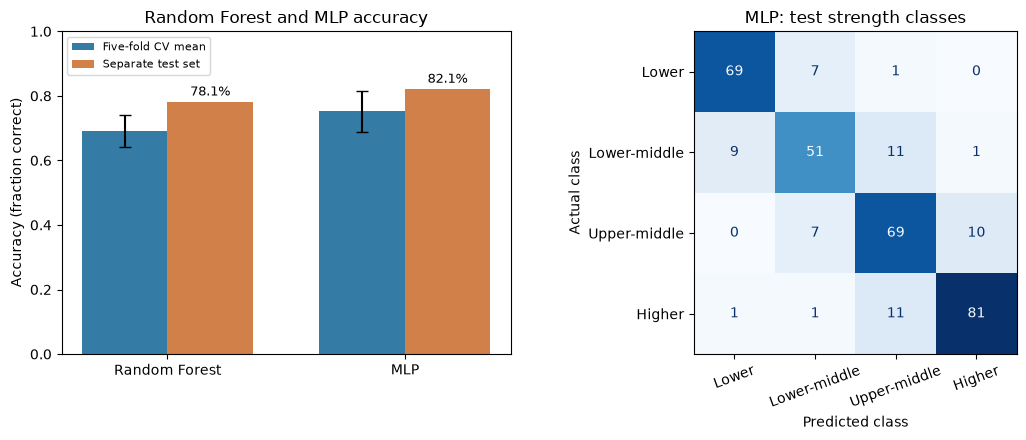

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
positions = np.arange(len(comparison))
axes[0].bar(positions-.18, comparison.cv_accuracy_mean, width=.36,
             label='Five-fold CV mean', color='#347ca5')
axes[0].bar(positions+.18, comparison.test_accuracy, width=.36,
             label='Separate test set', color='#d08048')
axes[0].errorbar(positions-.18, comparison.cv_accuracy_mean,
    yerr=comparison.cv_accuracy_sd, fmt='none', color='black', capsize=4)
axes[0].set(xticks=positions, xticklabels=comparison.model,
             ylim=(0, 1), ylabel='Accuracy (fraction correct)',
             title='Random Forest and MLP accuracy')
axes[0].legend(fontsize=8)
for i, value in enumerate(comparison.test_accuracy):
    axes[0].text(i+.18,value+.02,f'{value:.1%}',ha='center',fontsize=9)
ConfusionMatrixDisplay.from_predictions(y_test, mlp_prediction,
    labels=range(4), display_labels=CLASS_NAMES, cmap='Blues', values_format='d',
    colorbar=False, ax=axes[1], xticks_rotation=20)
axes[1].set(title='MLP: test strength classes',
             xlabel='Predicted class', ylabel='Actual class')
fig.tight_layout()
fig.savefig('figures/traditional_models_comparison.png', dpi=180)
plt.show()
plt.close(fig)

In [9]:
mlp_path = Path('models/mlp_baseline.pkl')
with mlp_path.open('wb') as stream:
    pickle.dump(mlp, stream, protocol=pickle.HIGHEST_PROTOCOL)
with mlp_path.open('rb') as stream:
    restored_mlp = pickle.load(stream)
np.testing.assert_array_equal(restored_mlp.predict(X_test),mlp_prediction)
pd.DataFrame({'source_row':test.source_row.to_numpy(),
              'actual_class':y_test.to_numpy(),
              'predicted_class':mlp_prediction}).to_csv(
    'results/mlp_test_predictions.csv',index=False)
pd.DataFrame({'iteration':np.arange(1,mlp.named_steps['model'].n_iter_+1),
              'training_loss':mlp.named_steps['model'].loss_curve_}).to_csv(
    'results/mlp_training_loss.csv',index=False)
best_traditional = comparison.loc[comparison.cv_accuracy_mean.idxmax(),'model']
checks_03 = {
    'iteration':3, 'date':'2026-11-01', 'student_id':'104999568',
    'name':'Pham Quang Minh', 'seed':SEED, 'source_sha256':source_hash,
    'features':FEATURES, 'class_names':CLASS_NAMES,
    'same_split_and_cv_folds_as_random_forest':True,
    'cv_scalers_fit_on_fold_training_only':True,
    'final_scaler_fit_on_training_only':True,
    'saved_model_predictions_match':True,
    'model_parameters':mlp.named_steps['model'].get_params(),
    'final_iterations':int(mlp.named_steps['model'].n_iter_),
    'cv_convergence_warnings':cv_convergence,
    'final_fit_convergence_warnings':fit_convergence,
    'metrics':mlp_metrics, 'best_traditional_by_cv_accuracy':best_traditional,
    'versions':metadata['versions'],
    'ai_assistance':'MLP example adaptation, explanations and checks'
}
Path('checks/iteration-03-checks.json').write_text(json.dumps(checks_03,indent=2))
print('Saved MLP pipeline, predictions, training loss and verification record.')
print('Traditional baseline selected by CV accuracy:', best_traditional)
print('Saved-model prediction check passed.')

Saved MLP pipeline, predictions, training loss and verification record.
Traditional baseline selected by CV accuracy: MLP
Saved-model prediction check passed.


## What the comparison shows
The MLP has **82.1% test accuracy** and weighted F1 **0.820**. Its mean CV accuracy is **75.2%**. The traditional baseline chosen by CV accuracy is **MLP**. Training accuracy (97.3%) is more optimistic than CV accuracy, so the training fit should not be treated as expected performance on new recipes. **6 fits issued a convergence warning** at the 500-iteration limit. Keep this limitation visible; no settings were changed after viewing test scores.

The MLP here is the scikit-learn baseline. The Keras ANN, dropout experiments and
training/validation curves belong to the next checkpoint and are not complete yet.

## Part B.1 - Prepare ANN fitting and validation data
Keep the same 329 test records. From the 676 training rows, reserve 20%
of recipe groups for validation. This gives **513 fitting rows and 163 validation
rows**. Groups have different sizes, so the row percentage differs from 20%.

The ANN's scaler learns only from the 513 fitting rows. Validation loss chooses
the saved weights; test data does not choose weights or settings. The traditional
models used all 676 training rows, so differences also reflect this smaller ANN
fitting set.

In [10]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
import tensorflow as tf
import keras
import h5py
from sklearn.model_selection import GroupShuffleSplit

tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.threading.set_inter_op_parallelism_threads(1)
tf.config.set_visible_devices([], 'GPU')
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
ann_plan = json.loads(Path('checks/ann_experiment_plan.json').read_text())
assert ann_plan['baseline']['max_epochs'] == 10
ann_split = GroupShuffleSplit(n_splits=1, test_size=.20, random_state=43)
ann_fit_idx, ann_val_idx = next(ann_split.split(X_train, y_train, groups))
assert set(groups[ann_fit_idx]).isdisjoint(groups[ann_val_idx])
assert set(groups).isdisjoint(test.recipe_group)
ann_scaler = StandardScaler().fit(X_train.iloc[ann_fit_idx])
X_ann_fit = ann_scaler.transform(X_train.iloc[ann_fit_idx]).astype('float32')
X_ann_val = ann_scaler.transform(X_train.iloc[ann_val_idx]).astype('float32')
X_ann_test = ann_scaler.transform(X_test).astype('float32')
y_ann_fit = y_train.iloc[ann_fit_idx].to_numpy(dtype='int32')
y_ann_val = y_train.iloc[ann_val_idx].to_numpy(dtype='int32')
assert X_ann_fit.shape == (513, 8) and X_ann_val.shape == (163, 8)
assert set(y_ann_fit) == set(y_ann_val) == set(range(4))
np.testing.assert_allclose(ann_scaler.mean_,
                           X_train.iloc[ann_fit_idx].mean().to_numpy())
ann_partition = train[['source_row','recipe_group']].copy()
ann_partition['ann_partition'] = 'fit'
ann_partition.iloc[ann_val_idx, ann_partition.columns.get_loc('ann_partition')] = 'validation'
ann_partition.to_csv('checks/ann_recipe_split.csv',index=False)
print('TensorFlow:', tf.__version__, '| Keras:', keras.__version__)
print('Fit:', X_ann_fit.shape, '| Validation:', X_ann_val.shape,
      '| Test:', X_ann_test.shape)
print('No recipes shared across ANN fit, validation and test.')

TensorFlow: 2.21.0 | Keras: 3.15.1
Fit: (513, 8) | Validation: (163, 8) | Test: (329, 8)
No recipes shared across ANN fit, validation and test.


## Part B.2 - Build the first ANN
Use the brief's 64, 32 and 16 hidden units, ReLU and two dropout layers of 0.2.
The output has four softmax units, one for each strength class. Adam uses learning
rate 0.001. Sparse cross-entropy accepts the existing integer class labels.

In [11]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
ann = tf.keras.Sequential([
    tf.keras.Input(shape=(len(FEATURES),)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(.2),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dropout(.2),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(4, activation='softmax')
],name='concrete_ann_baseline')
ann.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=.001),
    loss='sparse_categorical_crossentropy', metrics=['accuracy'])
assert ann.count_params() == 3252
ann.summary()

Model: "concrete_ann_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │            68 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,252 (12.70 KB)

 Trainable params: 3,252 (12.70 KB)

 Non-trainable params: 0 (0.00 B)

## Part B.3 - Train for up to 10 epochs
This first run uses batch size 32. Save the weights with the lowest validation
loss. Early stopping has patience 10; learning rate is halved after five epochs
without validation-loss improvement. With this short run, early stopping may not
activate. The controlled second experiment changes only the maximum epochs to 50.

In [12]:
ann_callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=10,
                                     restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss',factor=.5,
                                        patience=5,verbose=1),
    tf.keras.callbacks.ModelCheckpoint('models/ann_baseline_best.keras',
        monitor='val_loss',mode='min',save_best_only=True)
]
ann_history = ann.fit(X_ann_fit,y_ann_fit,
    validation_data=(X_ann_val,y_ann_val),epochs=10,batch_size=32,
    shuffle=True,callbacks=ann_callbacks,verbose=2)
ann_history_frame = pd.DataFrame(ann_history.history)
ann_history_frame.index = np.arange(1,len(ann_history_frame)+1)
ann_history_frame.index.name = 'epoch'
ann_history_frame.to_csv('results/ann_baseline_history.csv')
with Path('results/ann_baseline_history.pkl').open('wb') as stream:
    pickle.dump(ann_history.history,stream,protocol=pickle.HIGHEST_PROTOCOL)
selected_ann_epoch = int(ann_history_frame.val_loss.idxmin())
print('Completed epochs:',len(ann_history_frame))
print('Selected epoch by validation loss:',selected_ann_epoch)

Epoch 1/10


17/17 - 1s - 78ms/step - accuracy: 0.3353 - loss: 1.3637 - val_accuracy: 0.5031 - val_loss: 1.3011 - learning_rate: 0.0010


Epoch 2/10


17/17 - 0s - 7ms/step - accuracy: 0.4152 - loss: 1.3199 - val_accuracy: 0.5031 - val_loss: 1.2467 - learning_rate: 0.0010


Epoch 3/10


17/17 - 0s - 6ms/step - accuracy: 0.4425 - loss: 1.2687 - val_accuracy: 0.5092 - val_loss: 1.1822 - learning_rate: 0.0010


... (11 outputs left out)

17/17 - 0s - 10ms/step - accuracy: 0.5497 - loss: 1.0149 - val_accuracy: 0.6074 - val_loss: 0.9307 - learning_rate: 0.0010


Epoch 10/10


17/17 - 0s - 9ms/step - accuracy: 0.5302 - loss: 1.0203 - val_accuracy: 0.6012 - val_loss: 0.9078 - learning_rate: 0.0010


Completed epochs: 10
Selected epoch by validation loss: 10


In [13]:
# Always evaluate the validation-selected checkpoint, not an arbitrary final epoch.
ann_best = tf.keras.models.load_model('models/ann_baseline_best.keras')
ann_fit_eval = ann_best.evaluate(X_ann_fit,y_ann_fit,verbose=0,return_dict=True)
ann_val_eval = ann_best.evaluate(X_ann_val,y_ann_val,verbose=0,return_dict=True)
ann_test_eval = ann_best.evaluate(X_ann_test,y_test.to_numpy(),
                                  verbose=0,return_dict=True)
ann_probabilities = ann_best.predict(X_ann_test,verbose=0)
assert ann_probabilities.shape == (329,4)
assert np.isfinite(ann_probabilities).all()
np.testing.assert_allclose(ann_probabilities.sum(axis=1),1,atol=1e-6)
ann_predictions = ann_probabilities.argmax(axis=1)
ann_accuracy = float(accuracy_score(y_test,ann_predictions))
ann_weighted_f1 = float(f1_score(y_test,ann_predictions,
                                 average='weighted',zero_division=0))
assert np.isclose(ann_accuracy,ann_test_eval['accuracy'],atol=1e-6)
ann_metrics = {
    'model':'ANN (10 epochs)', 'train_accuracy':float(ann_fit_eval['accuracy']),
    'test_accuracy':ann_accuracy,'test_f1_weighted':ann_weighted_f1,
    'validation_accuracy':float(ann_val_eval['accuracy']),
    'validation_loss':float(ann_val_eval['loss']),
    'test_loss':float(ann_test_eval['loss']),
    'fit_rows':len(X_ann_fit),'validation_rows':len(X_ann_val),
    'max_epochs':10,'completed_epochs':len(ann_history_frame),
    'selected_epoch':selected_ann_epoch}
traditional_results = pd.read_csv('results/model_comparison.csv')
traditional_results = traditional_results.loc[
    traditional_results.model.isin(['Random Forest','MLP'])].copy()
master_results = pd.concat([traditional_results,pd.DataFrame([ann_metrics])],
                            ignore_index=True)
master_results.to_csv('results/model_comparison.csv',index=False)
print(master_results[['model','test_accuracy','test_f1_weighted']]
      .round(4).to_string(index=False))
print(f'ANN validation accuracy: {ann_val_eval["accuracy"]:.2%}')
print(f'ANN test loss: {ann_test_eval["loss"]:.4f}')
print(classification_report(y_test,ann_predictions,labels=range(4),
    target_names=CLASS_NAMES,digits=3,zero_division=0))
prediction_frame = pd.DataFrame({'source_row':test.source_row.to_numpy(),
    'actual_class':y_test.to_numpy(),'predicted_class':ann_predictions})
for k in range(4):prediction_frame[f'probability_{k}'] = ann_probabilities[:,k]
prediction_frame.to_csv('results/ann_baseline_test_predictions.csv',index=False)
pd.DataFrame(classification_report(y_test,ann_predictions,labels=range(4),
    target_names=CLASS_NAMES,output_dict=True,zero_division=0)).T.to_csv(
        'results/ann_baseline_classification_report.csv')

          model  test_accuracy  test_f1_weighted
  Random Forest         0.7812            0.7805
            MLP         0.8207            0.8203
ANN (10 epochs)         0.6231            0.5830
ANN validation accuracy: 60.12%
ANN test loss: 0.9325
              precision    recall  f1-score   support

       Lower      0.640     0.922     0.755        77
Lower-middle      0.512     0.292     0.372        72
Upper-middle      0.643     0.314     0.422        86
      Higher      0.637     0.915     0.751        94

    accuracy                          0.623       329
   macro avg      0.608     0.611     0.575       329
weighted avg      0.612     0.623     0.583       329



## Part B.4 - Inspect learning and predictions
Training and validation curves show whether learning is improving on both sets.
The model comparison is descriptive: the ANN reserves validation rows and has a
short 10-epoch budget, while the traditional models fit all 676 training rows.
The ANN has not had five-fold CV; its validation score is not a CV score.

Dropout is off during validation, so the validation curve can be above the training curve.

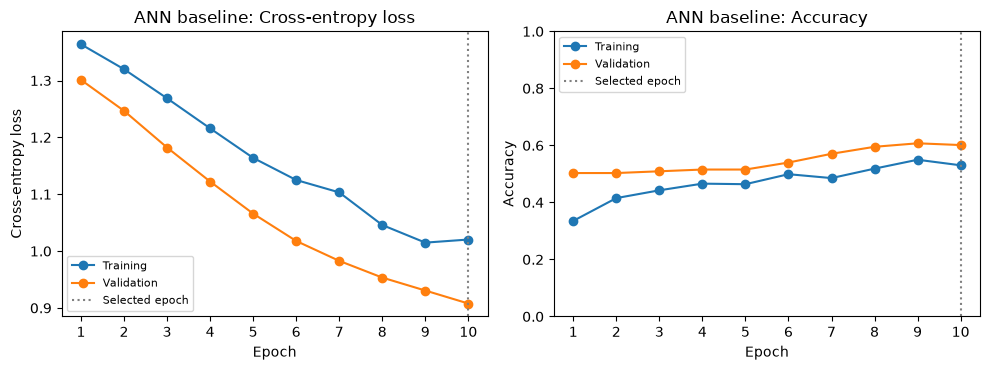

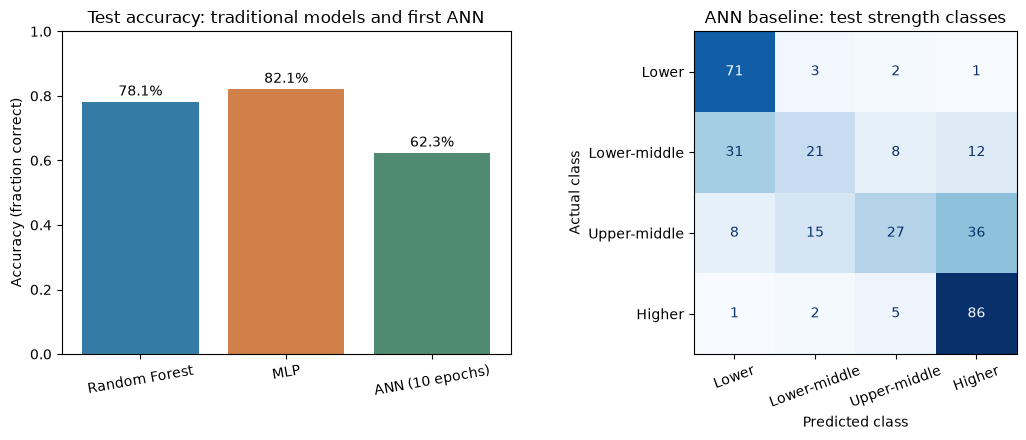

In [14]:
fig, axes = plt.subplots(1,2,figsize=(10,3.8))
for ax,metric,title in zip(axes,['loss','accuracy'],['Cross-entropy loss','Accuracy']):
    ax.plot(ann_history_frame.index,ann_history_frame[metric],marker='o',label='Training')
    ax.plot(ann_history_frame.index,ann_history_frame['val_'+metric],
             marker='o',label='Validation')
    ax.axvline(selected_ann_epoch,color='grey',linestyle=':',label='Selected epoch')
    ax.set(xlabel='Epoch',ylabel=title,title='ANN baseline: '+title)
    ax.set_xticks(ann_history_frame.index)
    ax.legend(fontsize=8)
axes[1].set_ylim(0,1)
fig.tight_layout()
fig.savefig('figures/ann_baseline_learning_curves.png',dpi=180)
plt.show()
plt.close(fig)

fig, axes = plt.subplots(1,2,figsize=(11,4.5))
bars = axes[0].bar(master_results.model,master_results.test_accuracy,
                    color=['#347ca5','#d08048','#508a70'])
for bar,value in zip(bars,master_results.test_accuracy):
    axes[0].text(bar.get_x()+bar.get_width()/2,value+.02,f'{value:.1%}',ha='center')
axes[0].set(title='Test accuracy: traditional models and first ANN',
             ylabel='Accuracy (fraction correct)',ylim=(0,1))
axes[0].tick_params(axis='x',rotation=10)
ConfusionMatrixDisplay.from_predictions(y_test,ann_predictions,
    labels=range(4),display_labels=CLASS_NAMES,cmap='Blues',values_format='d',
    colorbar=False,ax=axes[1],xticks_rotation=20)
axes[1].set(title='ANN baseline: test strength classes',
             xlabel='Predicted class',ylabel='Actual class')
fig.tight_layout()
fig.savefig('figures/ann_baseline_comparison.png',dpi=180)
plt.show()
plt.close(fig)

## Part B.5 - Save and verify the ANN
Save the model in the required H5 format, plus its scaler and training history.
The native Keras checkpoint also preserves the validation-selected model.
Reload the H5 model and check its predictions against the recorded results.

In [15]:
ann_best.save('models/ann_baseline_10epochs.h5')
with Path('models/ann_baseline_scaler.pkl').open('wb') as stream:
    pickle.dump(ann_scaler,stream,protocol=pickle.HIGHEST_PROTOCOL)
ann_restored = tf.keras.models.load_model('models/ann_baseline_10epochs.h5',compile=False)
restored_probabilities = ann_restored.predict(X_ann_test,verbose=0)
np.testing.assert_allclose(restored_probabilities,ann_probabilities,rtol=1e-6,atol=1e-7)
np.testing.assert_array_equal(restored_probabilities.argmax(axis=1),ann_predictions)
with Path('results/ann_baseline_history.pkl').open('rb') as stream:
    saved_history = pickle.load(stream)
np.testing.assert_allclose(saved_history['val_loss'],ann_history_frame.val_loss)
assert np.isfinite(ann_history_frame.to_numpy()).all()
assert len(ann_history_frame) <= 10
assert ann_best.count_params() == 3252
checks_04 = {
    'iteration':4,'date':'2026-11-01','name':'Pham Quang Minh',
    'student_id':'104999568','github':'https://github.com/theh9j/COS40007',
    'source_sha256':source_hash,'features':FEATURES,'class_names':CLASS_NAMES,
    'fit_rows':len(X_ann_fit),'validation_rows':len(X_ann_val),'test_rows':len(X_ann_test),
    'fit_recipe_groups':int(len(set(groups[ann_fit_idx]))),
    'validation_recipe_groups':int(len(set(groups[ann_val_idx]))),
    'shared_recipes_across_partitions':0,
    'scaler_fit_on_ann_fitting_rows_only':True,
    'architecture':[64,32,16,4],'dropout':[.2,.2],
    'parameter_count':int(ann_best.count_params()),
    'batch_size':32,'max_epochs':10,'completed_epochs':len(ann_history_frame),
    'selected_epoch_by_validation_loss':selected_ann_epoch,
    'selection_used_test_results':False,
    'metrics':ann_metrics,'saved_h5_predictions_match':True,'history_reload_matches':True,
    'cpu_only':True,'deterministic_ops':True,'seed':42,'split_seed':43,
    'early_stopping_patience':10,'reduce_lr_patience':5,'reduce_lr_factor':.5,
    'versions':{'python':platform.python_version(),'tensorflow':tf.__version__,
                'keras':keras.__version__,'h5py':h5py.__version__,
                'numpy':np.__version__,'pandas':pd.__version__,'sklearn':sklearn.__version__},
    'cv_performed_for_ann':False,
    'next_experiment':'Same configuration and split; increase only epoch budget to 50',
    'ai_assistance':'ANN example adaptation, validation setup, plots and verification'}
Path('checks/iteration-04-checks.json').write_text(json.dumps(checks_04,indent=2))
print('Saved H5 model, native Keras checkpoint, scaler and training history.')
print('Reloaded predictions, training-only scaling and history checks passed.')

Saved H5 model, native Keras checkpoint, scaler and training history.
Reloaded predictions, training-only scaling and history checks passed.


## What the first ANN run shows
The 10-epoch ANN has **62.3% test accuracy**, weighted F1 **0.583**, and test loss **0.932**. Its validation accuracy is **60.1%**. The saved model comes from epoch **10**, selected by validation loss. This is a short starting run, not a claim that the ANN is fully trained or better than the traditional baselines.

The controlled variation below keeps the split, seed, layers, dropout, batch size
and callbacks unchanged and raises only the epoch budget from 10 to 50. This
comparison was specified before inspecting ANN test results.

## Part B.6 - Controlled ANN variation
Increase only the maximum training budget from 10 to 50 epochs, as planned before
the first ANN test. Keep the same layers, dropout, batch size, seed, scaler and
recipe partitions. Start again from the same seed, rather than continuing from
the first model's trained weights.

Check that the first ten epochs reproduce the earlier history. Choose saved
weights and the preferred ANN using validation loss, not test accuracy. Early
stopping can end the run before epoch 50.

In [3]:
ann_plan = json.loads(Path('checks/ann_experiment_plan.json').read_text())
assert ann_plan['next_iteration']['max_epochs'] == 50
assert ann_plan['batch_size'] == 32 and ann_plan['seed'] == SEED
baseline_ann_checks = json.loads(Path('checks/iteration-04-checks.json').read_text())
baseline_ann_history = pd.read_csv('results/ann_baseline_history.csv',index_col='epoch')
baseline_ann_partition = pd.read_csv('checks/ann_recipe_split.csv')
assert set(baseline_ann_partition.query("ann_partition == 'fit'").source_row) ==        set(train.iloc[ann_fit_idx].source_row)
assert set(baseline_ann_partition.query("ann_partition == 'validation'").source_row) ==        set(train.iloc[ann_val_idx].source_row)
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
ann_long = tf.keras.Sequential([
    tf.keras.Input(shape=(len(FEATURES),)),
    tf.keras.layers.Dense(64,activation='relu'),
    tf.keras.layers.Dropout(.2),
    tf.keras.layers.Dense(32,activation='relu'),
    tf.keras.layers.Dropout(.2),
    tf.keras.layers.Dense(16,activation='relu'),
    tf.keras.layers.Dense(4,activation='softmax')
],name='concrete_ann_baseline')
ann_long.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=.001),
    loss='sparse_categorical_crossentropy',metrics=['accuracy'])
assert ann_long.count_params() == 3252
ann_long.summary()

Model: "concrete_ann_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │            68 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,252 (12.70 KB)

 Trainable params: 3,252 (12.70 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
long_callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=10,
                                     restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss',factor=.5,
                                        patience=5,verbose=1),
    tf.keras.callbacks.ModelCheckpoint('models/ann_extended_best.keras',
        monitor='val_loss',mode='min',save_best_only=True)
]
long_history = ann_long.fit(X_ann_fit,y_ann_fit,
    validation_data=(X_ann_val,y_ann_val),epochs=50,batch_size=32,
    shuffle=True,callbacks=long_callbacks,verbose=2)
long_history_frame = pd.DataFrame(long_history.history)
long_history_frame.index = np.arange(1,len(long_history_frame)+1)
long_history_frame.index.name = 'epoch'
long_history_frame.to_csv('results/ann_extended_history.csv')
with Path('results/ann_extended_history.pkl').open('wb') as stream:
    pickle.dump(long_history.history,stream,protocol=pickle.HIGHEST_PROTOCOL)
shared_history = ['loss','accuracy','val_loss','val_accuracy','learning_rate']
np.testing.assert_allclose(
    long_history_frame.loc[1:10,shared_history].to_numpy(),
    baseline_ann_history.loc[1:10,shared_history].to_numpy(),rtol=1e-6,atol=1e-7)
long_selected_epoch = int(long_history_frame.val_loss.idxmin())
print('First ten epochs match the baseline history.')
print('Completed epochs:',len(long_history_frame))
print('Selected epoch by validation loss:',long_selected_epoch)

Epoch 1/50


17/17 - 1s - 59ms/step - accuracy: 0.3353 - loss: 1.3637 - val_accuracy: 0.5031 - val_loss: 1.3011 - learning_rate: 0.0010


Epoch 2/50


17/17 - 0s - 6ms/step - accuracy: 0.4152 - loss: 1.3199 - val_accuracy: 0.5031 - val_loss: 1.2467 - learning_rate: 0.0010


Epoch 3/50


17/17 - 0s - 6ms/step - accuracy: 0.4425 - loss: 1.2687 - val_accuracy: 0.5092 - val_loss: 1.1822 - learning_rate: 0.0010


... (91 outputs left out)

17/17 - 0s - 4ms/step - accuracy: 0.7096 - loss: 0.6993 - val_accuracy: 0.6871 - val_loss: 0.6559 - learning_rate: 0.0010


Epoch 50/50


17/17 - 0s - 5ms/step - accuracy: 0.7251 - loss: 0.6777 - val_accuracy: 0.7239 - val_loss: 0.6525 - learning_rate: 0.0010


First ten epochs match the baseline history.
Completed epochs: 50
Selected epoch by validation loss: 50


In [5]:
ann_long_best = tf.keras.models.load_model('models/ann_extended_best.keras')
long_fit_eval = ann_long_best.evaluate(X_ann_fit,y_ann_fit,verbose=0,return_dict=True)
long_val_eval = ann_long_best.evaluate(X_ann_val,y_ann_val,verbose=0,return_dict=True)
# Decide which ANN to prefer before evaluating the new model on the test set.
preferred_ann = ('ANN (up to 50 epochs)' if long_val_eval['loss'] <
    baseline_ann_checks['metrics']['validation_loss'] else 'ANN (10 epochs)')
long_test_eval = ann_long_best.evaluate(X_ann_test,y_test.to_numpy(),
                                       verbose=0,return_dict=True)
long_probabilities = ann_long_best.predict(X_ann_test,verbose=0)
long_predictions = long_probabilities.argmax(axis=1)
assert long_probabilities.shape == (329,4)
assert np.isfinite(long_probabilities).all()
np.testing.assert_allclose(long_probabilities.sum(axis=1),1,atol=1e-6)
long_metrics = {
    'model':'ANN (up to 50 epochs)',
    'train_accuracy':float(long_fit_eval['accuracy']),
    'test_accuracy':float(accuracy_score(y_test,long_predictions)),
    'test_f1_weighted':float(f1_score(y_test,long_predictions,
                                     average='weighted',zero_division=0)),
    'validation_accuracy':float(long_val_eval['accuracy']),
    'validation_loss':float(long_val_eval['loss']),
    'test_loss':float(long_test_eval['loss']),
    'fit_rows':len(X_ann_fit),'validation_rows':len(X_ann_val),
    'max_epochs':50,'completed_epochs':len(long_history_frame),
    'selected_epoch':long_selected_epoch}
assert np.isclose(long_metrics['test_accuracy'],long_test_eval['accuracy'],atol=1e-6)
existing_results = pd.read_csv('results/model_comparison.csv')
existing_results = existing_results.loc[
    existing_results.model.isin(['Random Forest','MLP','ANN (10 epochs)'])].copy()
master_results = pd.concat([existing_results,pd.DataFrame([long_metrics])],ignore_index=True)
master_results.to_csv('results/model_comparison.csv',index=False)
ann_variants = master_results[master_results.model.str.startswith('ANN')].copy()
ann_variants[['model','max_epochs','completed_epochs','selected_epoch',
    'validation_loss','validation_accuracy','test_accuracy','test_f1_weighted']].to_csv(
        'results/ann_variants_comparison.csv',index=False)
print(master_results[['model','test_accuracy','test_f1_weighted']]
      .round(4).to_string(index=False))
print('Preferred ANN by validation loss:',preferred_ann)
print(classification_report(y_test,long_predictions,labels=range(4),
    target_names=CLASS_NAMES,digits=3,zero_division=0))
long_prediction_frame = pd.DataFrame({'source_row':test.source_row.to_numpy(),
    'actual_class':y_test.to_numpy(),'predicted_class':long_predictions})
for k in range(4):long_prediction_frame[f'probability_{k}'] = long_probabilities[:,k]
long_prediction_frame.to_csv('results/ann_extended_test_predictions.csv',index=False)
pd.DataFrame(classification_report(y_test,long_predictions,labels=range(4),
    target_names=CLASS_NAMES,output_dict=True,zero_division=0)).T.to_csv(
        'results/ann_extended_classification_report.csv')

                model  test_accuracy  test_f1_weighted
        Random Forest         0.7812            0.7805
                  MLP         0.8207            0.8203
      ANN (10 epochs)         0.6231            0.5830
ANN (up to 50 epochs)         0.7568            0.7462
Preferred ANN by validation loss: ANN (up to 50 epochs)
              precision    recall  f1-score   support

       Lower      0.849     0.948     0.896        77
Lower-middle      0.661     0.542     0.595        72
Upper-middle      0.681     0.570     0.620        86
      Higher      0.786     0.936     0.854        94

    accuracy                          0.757       329
   macro avg      0.744     0.749     0.741       329
weighted avg      0.746     0.757     0.746       329



## Part B.7 - Compare the learning curves
The dashed line marks the original 10-epoch budget. The selected epoch has the
lowest validation loss, which may differ from the last epoch or best accuracy.
Training uses dropout; validation does not. The test comparison is descriptive,
and the traditional models still use more fitting rows than either ANN.

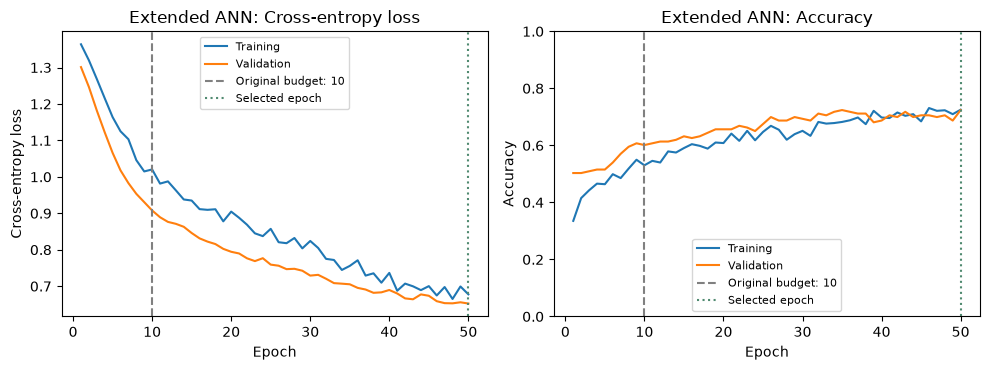

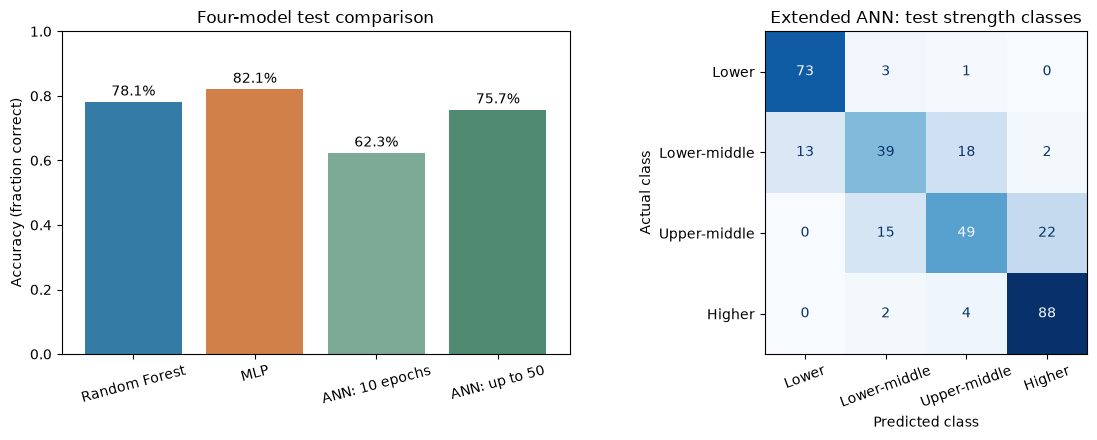

In [6]:
fig,axes = plt.subplots(1,2,figsize=(10,3.8))
for ax,metric,title in zip(axes,['loss','accuracy'],['Cross-entropy loss','Accuracy']):
    ax.plot(long_history_frame.index,long_history_frame[metric],label='Training')
    ax.plot(long_history_frame.index,long_history_frame['val_'+metric],label='Validation')
    ax.axvline(10,color='grey',linestyle='--',label='Original budget: 10')
    ax.axvline(long_selected_epoch,color='#508a70',linestyle=':',label='Selected epoch')
    ax.set(xlabel='Epoch',ylabel=title,title='Extended ANN: '+title)
    ax.legend(fontsize=8)
axes[1].set_ylim(0,1)
fig.tight_layout()
fig.savefig('figures/ann_extended_learning_curves.png',dpi=180)
plt.show()
plt.close(fig)

fig,axes = plt.subplots(1,2,figsize=(12,4.5))
chart_names = ['Random Forest','MLP','ANN: 10 epochs','ANN: up to 50']
bars = axes[0].bar(chart_names,master_results.test_accuracy,
    color=['#347ca5','#d08048','#7daa96','#508a70'])
for bar,value in zip(bars,master_results.test_accuracy):
    axes[0].text(bar.get_x()+bar.get_width()/2,value+.02,f'{value:.1%}',ha='center')
axes[0].set(title='Four-model test comparison',ylabel='Accuracy (fraction correct)',ylim=(0,1))
axes[0].tick_params(axis='x',rotation=15)
ConfusionMatrixDisplay.from_predictions(y_test,long_predictions,labels=range(4),
    display_labels=CLASS_NAMES,cmap='Blues',values_format='d',colorbar=False,
    ax=axes[1],xticks_rotation=20)
axes[1].set(title='Extended ANN: test strength classes',
             xlabel='Predicted class',ylabel='Actual class')
fig.tight_layout()
fig.savefig('figures/four_model_comparison.png',dpi=180)
plt.show()
plt.close(fig)

In [7]:
ann_long_best.save('models/ann_extended_50epochs.h5')
# Reuse the original fitted ANN scaler; do not fit a new one.
with Path('models/ann_baseline_scaler.pkl').open('rb') as stream:
    original_ann_scaler = pickle.load(stream)
np.testing.assert_allclose(original_ann_scaler.mean_,ann_scaler.mean_)
np.testing.assert_allclose(original_ann_scaler.scale_,ann_scaler.scale_)
long_restored = tf.keras.models.load_model('models/ann_extended_50epochs.h5',compile=False)
np.testing.assert_allclose(long_restored.predict(X_ann_test,verbose=0),
                           long_probabilities,rtol=1e-6,atol=1e-7)
with Path('results/ann_extended_history.pkl').open('rb') as stream:
    restored_history = pickle.load(stream)
np.testing.assert_allclose(restored_history['val_loss'],long_history_frame.val_loss)
assert np.isfinite(long_history_frame.to_numpy()).all()
assert 10 <= len(long_history_frame) <= 50
assert ann_long_best.count_params() == baseline_ann_checks['parameter_count'] == 3252
checks_05 = {
    'iteration':5,'date':'2026-11-01','name':'Pham Quang Minh','student_id':'104999568',
    'source_sha256':source_hash,'features':FEATURES,'class_names':CLASS_NAMES,
    'fit_rows':len(X_ann_fit),'validation_rows':len(X_ann_val),'test_rows':len(X_ann_test),
    'architecture':[64,32,16,4],'dropout':[.2,.2],'parameter_count':3252,
    'seed':42,'split_seed':43,'batch_size':32,'max_epochs':50,
    'completed_epochs':len(long_history_frame),'selected_epoch':long_selected_epoch,
    'same_first_ten_epochs_as_baseline':True,'same_saved_split':True,'same_scaler':True,
    'only_changed_setting':'Maximum epochs: 10 to 50',
    'callbacks':ann_plan['callbacks'],'selection_used_test_results':False,
    'preferred_ann_by_validation_loss':preferred_ann,
    'validation_loss_improvement':float(baseline_ann_checks['metrics']['validation_loss']-
                                       long_val_eval['loss']),
    'metrics':long_metrics,'saved_h5_predictions_match':True,'history_reload_matches':True,
    'versions':baseline_ann_checks['versions'],'cv_performed_for_ann':False,
    'ai_assistance':'Controlled experiment implementation, plots and verification'}
Path('checks/iteration-05-checks.json').write_text(json.dumps(checks_05,indent=2))
print('Saved extended ANN, history, predictions and verification record.')
print('Prefix history, original split/scaler and H5 reload checks passed.')

Saved extended ANN, history, predictions and verification record.
Prefix history, original split/scaler and H5 reload checks passed.


## What the controlled variation shows
The extended ANN completed **50 epochs** and selected epoch **50** by validation loss. Test accuracy is **75.7%**, weighted F1 **0.746**, and validation accuracy **72.4%**. The preferred ANN by validation loss is **ANN (up to 50 epochs)**. The first ten epochs reproduce the original run, supporting that the training budget was the only experimental change. Test scores alone do not establish which model will generalise best.

All planned model runs are now recorded. The next iteration is the concise PDF,
final checks and an honest GenAI reflection. Personal learning answers still need
the student's own input.

## Part C - Final report and reflection
All four model results are available. The concise PDF and final interpretation will be completed next. Personal learning reflections remain for the student to write.

## Attribution and progress
Data: Yeh, I. (1998). Concrete Compressive Strength. UCI Machine Learning Repository.
https://doi.org/10.24432/C5PK67. CC BY 4.0. Data and fixed labels come from Portfolio 2.

Random Forest and CV APIs: scikit-learn documentation.
https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html

**AI-assisted:** baseline implementation, explanations and verification using OpenAI
Codex. This assistance should be recorded honestly in the final GenAI reflection;
the code still needs the student's review under the course's permitted-use rules.
Personal learning reflections have not been written on the student's behalf.

See `PROGRESS.md` for this checkpoint and the next step.

Checkpoint 3 adapts the supplied `MLP_Classifcation.ipynb` (Iris example) to the concrete inputs and saved recipe folds. AI-assisted: adaptation, explanation and verification.
https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html

Checkpoint 4 adapts the tabular ANN teaching example to four-class concrete data and the specified 64/32/16 architecture. AI-assisted: implementation, validation design, explanations and checks.
https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/EarlyStopping
https://keras.io/api/callbacks/model_checkpoint/

Checkpoint 5: AI-assisted controlled experiment, plots and verification. Only the epoch budget changed, as specified before the first ANN evaluation.